# Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from metatopia.utils import (
    MEDIUM_FIG,
    plot_design,
    plot_losses,
    plot_meta_losses,
    plot_performance_profiles,
    SMALL_FIG,
)
from post_process_utils import MetaTestResults


[INFO 02-04 10:31:49] metatopia: Running version 0.0.2 on the GPU.


# Read and plot the meta-test results

In [3]:
meta_path = Path("/home/igork/projects/saved_runs/NewExperiments/24-01_10-34")
mma_path = Path("/home/igork/projects/saved_runs/NewExperiments/24-01_10-34")
std_path = Path("/home/igork/projects/saved_runs/NewExperiments/24-01_10-34")

dataset_name = "test_id"
steps = 200

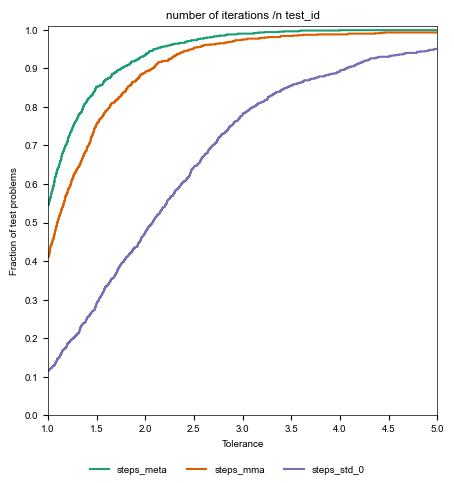

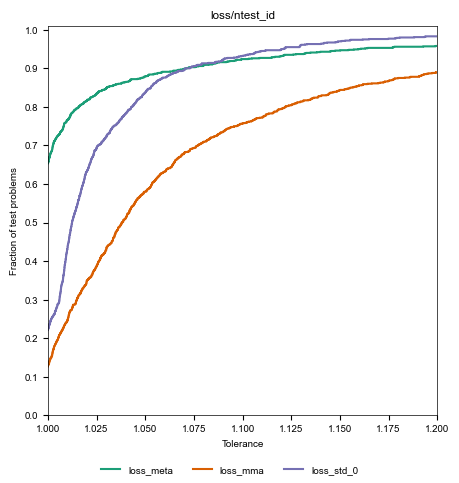

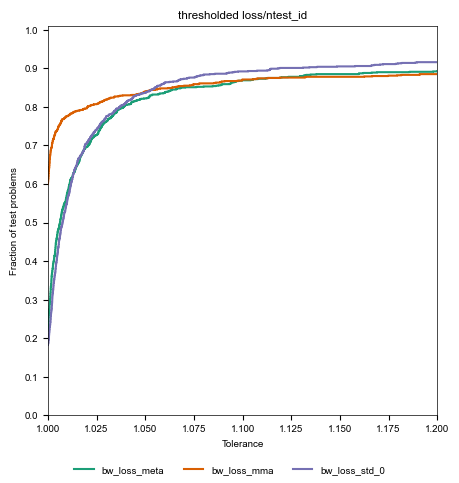

In [4]:
# Load test results
results = MetaTestResults.from_path(
    results_path=meta_path,
    steps=steps,
    dataset_name=dataset_name,
)

df = results.to_df()
# df = extract_multi_trial_df(trials = [results_meta, results_mma],
#                             model_selections=[["meta"], ["mma"]],
#                             )


# NOTE [MMA PATHS ARE CORRUPTED FOR OOD NOW]
solver_names = ["meta", "std_0", "mma"]
# # Custom subset
fig, ax = plot_performance_profiles(
    df,
    solver_names,
    metric="steps",
    dataset_name=dataset_name,
    x_limit=5,
    title=f"number of iterations /n {dataset_name}",
)

fig, ax = plot_performance_profiles(
    df,
    solver_names,
    metric="loss",
    dataset_name=dataset_name,
    x_limit=1.2,
    title=f"loss/n{dataset_name}",
)

fig, ax = plot_performance_profiles(
    df,
    solver_names,
    metric="bw_loss",
    dataset_name=dataset_name,
    x_limit=1.2,
    title=f"thresholded loss/n{dataset_name}",
)

# Plot meta losses

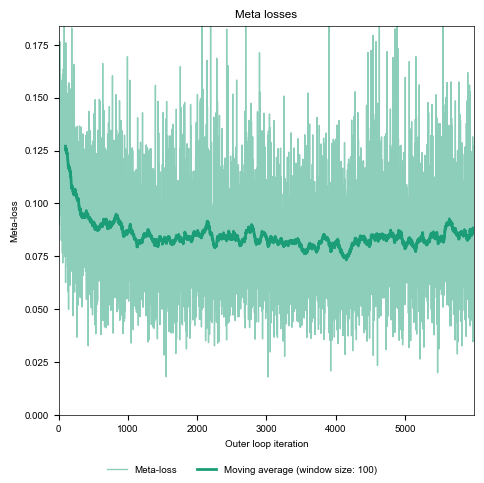

In [5]:
# Plot the meta losses
meta_losses = np.load(meta_path / "meta_losses.npy")
fig, axes = plot_meta_losses(
    meta_losses, clip_percentile=100, title="Meta losses", legend=True
)

# Plot average loss across test tasks

ids [30903 30984 30300 30705 30961 30743 30788 30055 30094 30786 30431 30591
 30250 30143 30504 30872 30162 30172 30000 30805 30965 30549 30182 30521
 30807 30282 30287 30999 30254 30679 30465 30098 30088 30815 30610 30003
 30795 30288 30936 30211 30507 30539 30420 30114 30100 30440 30306 30390
 30010 30829 30548 30038 30771 30592 30061 30634 30573 30388 30890 30107
 30793 30847 30158 30091 30126 30097 30059 30604 30083 30685 30175 30327
 30911 30708 30063 30462 30365 30110 30602 30023 30352 30933 30109 30742
 30168 30730 30586 30378 30733 30001 30804 30710 30073 30276 30723 30712
 30413 30067 30348 30825 30828 30209 30129 30385 30186 30202 30597 30764
 30516 30833 30658 30624 30520 30841 30433 30514 30635 30065 30363 30704
 30632 30184 30216 30277 30222 30838 30928 30888 30237 30638 30943 30900
 30255 30470 30922 30528 30831 30133 30995 30338 30336 30473 30886 30361
 30620 30012 30272 30625 30778 30699 30344 30864 30164 30851 30264 30608
 30777 30858 30474 30785 30796 30510 30867 3003

FileNotFoundError: No trajectory found for meta, id 30961

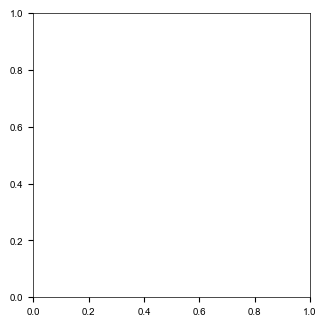

In [6]:
colors = sns.color_palette("Dark2")

models = ["meta", *[f"std_{i}" for i in range(0, 3)]]  # Add all your models here
ids = df["id"].unique()

print("ids", ids)

fig, ax = plt.subplots(figsize=(SMALL_FIG, SMALL_FIG), layout="constrained")

for i, model in enumerate(sorted(models)):
    all_losses = []
    for id in ids:
        # Skip if not found
        losses = results.get_losses(model, id)

        print("model", model, "id", id, "losses", losses)
        # losses = results.get_losses(model, id)
        # losses = np.pad(losses, (0, steps - len(losses)), mode="edge")
        all_losses.append(losses)

    stacked = np.stack(all_losses)
    mean_losses = np.mean(stacked, axis=0)


    fig, ax = plot_losses(
        mean_losses, max_steps=steps, name=model, legend=True, ax=ax, color=colors[i]
    )

    ax.set_xlim(0, 20)


plt.grid(True)
# plt.title("Average loss across in-distribution tasks")
plt.show()

Found 0 common IDs


ValueError: need at least one array to stack

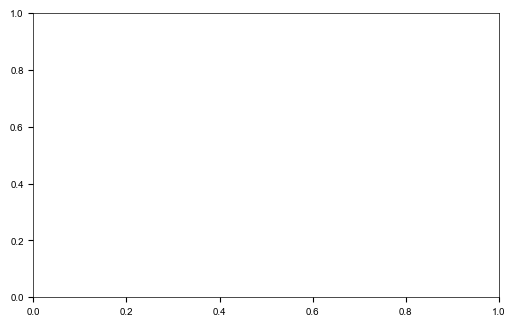

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


# make fonts editable in illustrator
plt.rcParams["pdf.fonttype"] = 42

model_labels = {
    "meta": "meta-neural TO",
    "mma": "standard TO",
    "std_0": "neural TO (0)",
    "std_1": "neural TO (1)",
    "std_2": "neural TO (2)",
}

model_colors = {
    "meta": 0,
    "mma": 2,
    "std_0": 1,
    "std_1": 3,
    "std_2": 4,
}


def plot_with_confidence_intervals(df, results, models, n_samples=5):
    colors = sns.color_palette("Dark2")
    
    # Find IDs that exist in all models
    common_ids = set()
    first_model = True
    
    for model in models:
        model_ids = set()
        for id in df["id"].unique():
            try:
                results.get_losses(model, id)
                model_ids.add(id)
            except KeyError:
                continue
        
        if first_model:
            common_ids = model_ids
            first_model = False
        else:
            common_ids = common_ids.intersection(model_ids)
    
    # Convert to list for indexing
    common_ids = list(common_ids)
    print(f"Found {len(common_ids)} common IDs")
    
    fig, ax = plt.subplots(figsize=(1.6*SMALL_FIG, SMALL_FIG), layout="constrained")

    for i, model in enumerate(models):
        color = colors[model_colors[model]]

        all_losses = []
        for id in common_ids:
            losses = results.get_losses(model, id)
            all_losses.append(losses)

        stacked = np.stack(all_losses)
        mean_losses = np.mean(stacked, axis=0)
        std_losses = np.std(stacked, axis=0)

        # Plot confidence intervals
        ax.fill_between(
            range(len(mean_losses)),
            mean_losses - std_losses,
            mean_losses + std_losses,
            alpha=0.2,
            color=color,
            label=f"{model_labels[model]} ±1σ (68% CI)",
        )

        # Plot mean line
        plot_losses(
            mean_losses,
            max_steps=steps,
            name=model,
            legend=True,
            ax=ax,
            color=color,
            label=model_labels[model],
        )

        # Plot random sample of individual problems
        random_indices = np.random.choice(len(all_losses), n_samples, replace=False)
        for num, idx in enumerate(random_indices):
            ax.plot(
                all_losses[idx],
                color=color,
                alpha=0.25,
                linewidth=1,
                linestyle="-",
                label=f"{model_labels[model]} sample trajectories"
                if num == 0
                else None,
            )

    ax.set_xlim(0, steps)
    # ax.set_ylim(0, 1)
    ax.grid(True)
    # ax.set_title("Average loss across in-distribution test tasks")
    ax.set_xlabel("Steps")
    ax.set_ylabel("Loss")
    ax.legend()

    return fig, ax


# Usage:
fig, ax = plot_with_confidence_intervals(df, results, models, n_samples=0)
plt.savefig("losses.pdf", dpi=300)

In [11]:
# id = 30_500
# design = results.get_design(model_name="std_0", id_=id)

# problem = results.get_problem(id)

# fig, ax = plot_design(
#     problem["strain_energy"], problem, colorbar=True, cmap="rainbow", vmin=-1, vmax=1
# )
# plt.savefig("example_strain_field.pdf", dpi=300)

In [ ]:
id = 0
selected_ids = [0]

n_models = len(models)
n_samples = len(selected_ids)

fig, axes = plt.subplots(
    n_samples,
    n_models,
    figsize=(MEDIUM_FIG, MEDIUM_FIG),
    layout="constrained",
    squeeze=False,
)


for col, model in enumerate(models):
    problem = results.get_problem(0)
    design = results.get_design(model_name=model, id_=0)
    plot_design(design, ax=axes[0, col], colorbar=False)
    axes[0, col].set_title(model_labels[model])

# axes[0, 0].set_title("Neural TO")
# axes[0, 1].set_title("Meta-Neural TO")
# axes[0, 2].set_title("Standard TO")


plt.savefig("example_designs.pdf", dpi=300)
